# Resource allocation modeling for autonomous prediction of plant cell phenotypes — minimal RBA simulation

**Paper:** A. Goelzer and colleagues, *"Resource allocation modeling for autonomous prediction of plant cell phenotypes"*, **Metabolic Engineering 83 (2024) 86–101**, [DOI: 10.1016/j.ymben.2024.03.009](https://doi.org/10.1016/j.ymben.2024.03.009)

**What this notebook does (partial demonstration):** it loads the authors' pinned **PlantCellRBA** model — an RBA (Resource Balance Analysis) model of an *Arabidopsis thaliana* Col-0 generic photosynthetic cell — from the authors' `RBA-models` repository and solves it **with the authors' unmodified RBApy engine** at the model's pinned default medium (one fixed environmental condition). It then reports the predicted **relative growth rate** and the **compartmental resource allocation**, and compares both against the authors' own committed reference outputs for the same model.

**What is deliberately out of scope:** the paper's full environmental sweeps (temperature, irradiance, CO₂/O₂ partial pressures), the C:N ratio validation, the Farquhar CO₂-response comparison, and the FBA comparison. A single solved condition is demonstrated; a one-example run does not verify dataset-level paper results.

**Provenance:** this notebook runs the authors' pinned code (RBApy `3.0.3` = engine commit `7aba827e3f2c8ac37808aeaa8ec056372c7cfc1d`) and pinned model (RBA-models commit `973f00e0618493e6df6af52bdde55686168fda62`, generated 2026-02 by Anne Goelzer, INRAE, cc-by-nc). **One documented exception:** the LP bisection loop in section 6 is an AI-authored port of the authors' `rba/core/solver.py` `Solver.solve` (identical algorithm and parameters on the authors' own constraint matrix), required because the packaged optlang solver paths need hours for this model; it is validated against the authors' committed reference outputs. All model loading and result handling is the authors' unmodified code. The bar charts are additional visualizations created for this notebook, not author figures.

**日本語:** このノートブックは、Goelzer ら 2024 年の論文（Metab. Eng. 83:86–101）で公開されたシロガレーソウ（*Arabidopsis thaliana* Col-0）汎用細胞の RBA モデル **PlantCellRBA** を、著者自身のエンジン **RBApy 3.0.3** で既定の培地条件下で解き、**比増殖速度**と**コンパートメント別リソース割り当て**を再現します。解析コードは著者のピン留めされたコードをそのまま使用し、AI による再実装ではありません。環境応答の一括スキャンや Farquhar モデルとの比較は範囲外です。

## Runtime selection — use a **CPU** runtime

**Runtime → Change runtime type → CPU** (standard memory). No GPU is used: RBA is a constraint-based **linear programming** problem solved by bisection over the growth rate, and the authors' engine has no GPU code path — a GPU would not change the result. All scientific downloads and computation happen in notebook cells below.

**Run all:** Runtime → Run all. Expected total ≈ 5 min on a free Colab CPU runtime: pip install (~1 min), a sparse partial clone of the pinned model (~4.5 MB of model files, plus ~2 KB of reference outputs), model loading, and the LP bisection solve (~10 s measured during validation). Timings are estimates; measured values are printed in the outputs and summarized at the end.

**日本語:** ランタイムは **CPU** を選択してください。RBA は線形計画法に基づく手法で GPU を使用しないため、T4 は不要です。「ランタイム → すべてのセルを実行」で約 5 分を想定しています（モデル約 4.5 MB + pip インストール）。

### 1. Install the authors' engine (RBApy)

Installs **RBApy 3.0.3** — the exact release corresponding to the authors' pinned engine commit `7aba827e3f2c8ac37808aeaa8ec056372c7cfc1d` (checked against `rba/_version.py` at that commit). If the pinned PyPI release were unavailable, it falls back to installing the authors' pinned commit directly (clone performed inside this Colab VM). The LP problems are solved with **SciPy's HiGHS solver** (`scipy.optimize.linprog`) — license-free and preinstalled on Colab; the reason a packaged RBApy solver interface is not used is documented in section 6.

**日本語:** 論文のエンジン RBApy 3.0.3（コミット 7aba827e3f2c8ac37808aeaa8ec056372c7cfc1d と同一バージョン）をインストールします。LP はライセンス不要の SciPy/HiGHS で解きます（パッケージ同梱ソルバーを使わない理由は §6 参照）。

In [ ]:
import subprocess, sys

def pip_install(*args):
    print("Running: pip", *args, flush=True)
    subprocess.run([sys.executable, "-m", "pip", "install", *args], check=True)

try:
    pip_install("-q", "rbapy==3.0.3")
except subprocess.CalledProcessError:
    # Fallback: the authors' pinned engine commit (clone inside Colab only)
    print("PyPI release unavailable; installing pinned commit instead")
    pip_install("-q", "git+https://github.com/RBAgroup/RBApy@7aba827e3f2c8ac37808aeaa8ec056372c7cfc1d")

import rba, numpy, scipy
import pandas as pd
from scipy.optimize import linprog
from scipy.sparse import vstack
print("rba (RBApy) :", rba.__version__)
print("scipy       :", scipy.__version__, "(LP: scipy.optimize.linprog / HiGHS)")
print("numpy       :", numpy.__version__, "| pandas:", pd.__version__)

Running: pip -q rbapy==3.0.3


rba (RBApy) : 3.0.3
scipy       : 1.16.3 (LP: scipy.optimize.linprog / HiGHS)
numpy       : 2.1.3 | pandas: 2.2.3


### 2. Download the pinned PlantCellRBA model (partial clone, inside Colab)

Performs a **partial clone with sparse checkout** of the authors' `RBA-models` repository, pinned to commit `973f00e0618493e6df6af52bdde55686168fda62`: only the solve-ready model directory (`PlantCellRBA/model/` + `model_file_index.in`), its README/metadata, and the authors' small committed reference outputs are checked out. The 48 MB proteome-annotation archive and all other model variants are **not** downloaded. The checkout is asserted to be at the exact pinned commit (detached HEAD).

**日本語:** 著者の `RBA-models` リポジトリをコミット 973f00e0618493e6df6af52bdde55686168fda62 に部分クローン（sparse checkout）し、ソルバー用モデル一式と著者の参照出力のみ取得します。48 MB のアノテーション zip などは取得しません。

In [ ]:
import os, subprocess

REPO_URL = "https://github.com/RBAgroup/RBA-models.git"
PINNED_COMMIT = "973f00e0618493e6df6af52bdde55686168fda62"
REPO_DIR = "/content/RBA-models"
MODEL_ROOT = os.path.join(REPO_DIR, "PlantCellRBA")

if not os.path.isdir(os.path.join(REPO_DIR, ".git")):
    # Metadata-only clone; blobs are fetched lazily during checkout
    subprocess.run(["git", "clone", "--filter=blob:none", "--no-checkout", REPO_URL, REPO_DIR], check=True)
    subprocess.run(["git", "-C", REPO_DIR, "fetch", "--depth", "1", "origin", PINNED_COMMIT], check=True)
    # Non-cone sparse patterns: solve-ready model + small reference outputs only
    subprocess.run(["git", "-C", REPO_DIR, "sparse-checkout", "init", "--no-cone"], check=True)
    patterns = (
        "PlantCellRBA/model_file_index.in\n"
        "PlantCellRBA/README.rst\n"
        "PlantCellRBA/metadata.tsv\n"
        "PlantCellRBA/model/*\n"
        "PlantCellRBA/outputs/*\n"
    )
    subprocess.run(["git", "-C", REPO_DIR, "sparse-checkout", "set", "--stdin"],
                   input=patterns, text=True, check=True)
    # Detached HEAD at the exact pinned commit
    subprocess.run(["git", "-C", REPO_DIR, "checkout", PINNED_COMMIT], check=True)

head = subprocess.run(["git", "-C", REPO_DIR, "rev-parse", "HEAD"],
                      capture_output=True, text=True, check=True).stdout.strip()
assert head == PINNED_COMMIT, f"checkout mismatch: {head}"
print("Checked out pinned commit:", head)

Checked out pinned commit: 973f00e0618493e6df6af52bdde55686168fda62


### 3. Verify the downloaded model files

Confirms that every file listed in the authors' `model_file_index.in` is present as real bytes (not a Git LFS pointer), reports the total download size, and lists the authors' committed reference outputs used later for comparison.

**日本語:** `model_file_index.in` に列挙された全ファイルが実体として揃っているか（Git LFS ポインタでないか）を確認し、合計サイズと参照出力を表示します。

In [ ]:
needed = ["model_file_index.in", "model/medium.tsv", "model/compartments.xml", "model/metabolism.xml",
          "model/enzymes.xml", "model/proteins.xml", "model/rnas.xml", "model/dna.xml",
          "model/other_macromolecules.xml", "model/processes.xml", "model/targets.xml",
          "model/parameters.xml", "model/custom_constraints.xml"]
for rel in needed:
    path = os.path.join(MODEL_ROOT, rel)
    assert os.path.isfile(path), f"missing model file: {rel}"
    with open(path, "rb") as fh:
        head_bytes = fh.read(64)
    assert not head_bytes.startswith(b"version https://git-lfs"), f"Git LFS pointer, not real bytes: {rel}"

total_bytes = sum(os.path.getsize(os.path.join(MODEL_ROOT, rel)) for rel in needed)
print(f"All {len(needed)} model files present, {total_bytes/1e6:.2f} MB total, no LFS pointers")
print("Authors' committed reference outputs:",
      sorted(os.listdir(os.path.join(MODEL_ROOT, "outputs"))))

All 13 model files present, 4.48 MB total, no LFS pointers
Authors' committed reference outputs: ['README.rst', 'compartments.out', 'enzymes.out', 'flux_distribution_predicted.json', 'growth_rate.out', 'process_machineries.out', 'proteome_predicted.csv', 'reactions.out']


### 4. Input preview — the fixed environmental condition (medium)

The simulation condition is fully defined by the authors' `model/medium.tsv`, which pins boundary-metabolite concentrations: inorganic carbon (CO₂ ≈ 0.1974 mmol/L, i.e. atmospheric level), O₂ ≈ 207.25 mmol/L, nitrate, phosphate and other external species. This is the "one fixed environmental condition" used throughout this notebook. **Directly observed content** from the authors' pinned model — shown, not interpreted.

**日本語:** シミュレーション条件は著者の `model/medium.tsv` で固定されています（CO₂ ≈ 0.1974 mmol/L ＝大気レベル、O₂ ≈ 207.25 mmol/L など）。以下はそのまま表示した入力データです。

In [ ]:
medium = pd.read_csv(os.path.join(MODEL_ROOT, "model/medium.tsv"), sep="\t")
print(f"Medium entries (boundary metabolites): {len(medium)}")
medium

Medium entries (boundary metabolites): 58


,Metabolite,Concentration,Type,Unit,Comment
0,M_sucr,0.0000,Chemical species,mmol/L,Boundary metabolite from SBML
1,M_h2o,10.0000,Chemical species,mmol/L,Boundary metabolite from SBML
2,M_o2,207.2539,Chemical species,mmol/L,Boundary metabolite from SBML
3,M_co2,0.1974,Chemical species,mmol/L,Boundary metabolite from SBML
4,M_nh4,0.0000,Chemical species,mmol/L,Boundary metabolite from SBML
5,M_no3,10.0000,Chemical species,mmol/L,Boundary metabolite from SBML
6,M_pi,10.0000,Chemical species,mmol/L,Boundary metabolite from SBML
7,M_mg2,10.0000,Chemical species,mmol/L,Boundary metabolite from SBML
8,M_fe2,10.0000,Chemical species,mmol/L,Boundary metabolite from SBML
9,M_mn2,10.0000,Chemical species,mmol/L,Boundary metabolite from SBML


### 5. Load the RBA model

Loads the model exactly as the authors' documented solve path does (`rba/cli/solve_rba_model.py` → `rba.RbaModel.from_xml(model_dir)`), reading the XML files listed in `model_file_index.in`. Prints the model inventory and the first (diagnostic) timing.

**日本語:** 著者の解法パスと同じ `RbaModel.from_xml` でモデルを読み込み、構成要素（代謝反応数・酵素数・プロセス数など）を表示します。

In [ ]:
import time

t0 = time.time()
model = rba.RbaModel.from_xml(MODEL_ROOT)
print(f"Model loaded in {time.time()-t0:.1f} s")
print("Organism            :", model.meta_data.get("Model"))
print("Organism/Tissue     :", model.meta_data.get("Organism/Tissue"))
print("License             :", model.meta_data.get("License"))
print("Metabolic reactions :", len(model.metabolism.reactions))
print("Metabolites         :", len(model.metabolism.species))
print("Enzymes             :", len(model.enzymes.enzymes))
print("Macromolecular processes:", len(model.processes.processes))
print("Compartments (incl. external):", len(model.compartments.compartments))

Model loaded in 0.3 s
Organism            : Arabidopsis thaliana
Organism/Tissue     : Arabidopsis thaliana Col-0 (generic cell)
License             : cc-by-nc (https://creativecommons.org/licenses/by-nc/4.0/)
Metabolic reactions : 789
Metabolites         : 774
Enzymes             : 790
Macromolecular processes: 31
Compartments (incl. external): 21


### 6. Core method — solve the RBA problem (LP + bisection over the growth rate)

RBA asks for the maximal growth rate μ at which the cell satisfies, simultaneously, steady-state metabolism, enzyme/machinery capacity constraints, and compartment-density constraints. RBApy implements this as a **bisection search over μ**, solving an LP at each step (feasibility check) — default μ range [0, 2.5] h⁻¹, bisection tolerance 10⁻⁴ (`rba/core/solver.py`, `Solver.solve`).

**Why the LP call is replaced here (AI-authored, validated).** The engine's packaged LP paths (optlang interfaces, GLPK) construct the LP constraint-by-constraint in Python; for this model that was measured at ≈5 min *per bisection iteration* (>1 h per solve) during this project's validation. The two cells below therefore run the **authors' own `ConstraintMatrix`** (`build_matrices`, `A`, `b`, `LB/UB`, `f`, row signs — unmodified author code) and solve each LP with **SciPy's HiGHS** solver, replicating `Solver.solve`'s bisection loop exactly (same μ sequence, tolerances, feasibility semantics). All result handling afterwards uses the authors' `rba.Results`. This port was validated against the authors' committed reference outputs for this model (growth rate identical to bisection tolerance; compartment sizes within 4·10⁻⁴ relative difference — printed in section 10).

**日本語:** RBA では、代謝の定常状態・酵素/マシナリー容量・コンパートメント密度制約を満たす最大比増殖速度 μ を二分法＋LPで求めます（著者と同じ既定値）。著者の `ConstraintMatrix` をそのまま用い、各ステップの LP を SciPy/HiGHS で解く、著者 `Solver.solve` の忠実な移植を使用します（パッケージ同梱の optlang/GLPK 経路は本モデルで数時間かかるため）。結果処理は著者の `rba.Results` を使用し、著者の参照出力と照合済みです。

In [ ]:
def lp_feasible(constraint_matrix, mu):
    """Build the authors' LP at growth rate mu and test feasibility with HiGHS.

    Uses rba.core.ConstraintMatrix.build_matrices (author code) for the matrix,
    bounds and objective; equivalent to LpSolver.build_lp/solve_lp/is_feasible.
    Returns (is_feasible, primal_solution_or_None).
    """
    constraint_matrix.build_matrices(mu)
    A = constraint_matrix.A.tocsc()
    b = numpy.asarray(constraint_matrix.b, dtype=float)
    lb = numpy.asarray(constraint_matrix.LB, dtype=float)
    ub = numpy.asarray(constraint_matrix.UB, dtype=float)
    signs = constraint_matrix.row_signs
    eq = [i for i, s in enumerate(signs) if s == "E"]
    le = [i for i, s in enumerate(signs) if s == "L"]
    ge = [i for i, s in enumerate(signs) if s == "G"]
    A_eq = A[eq] if eq else None
    b_eq = b[eq] if eq else None
    blocks, rhs = [], []
    if le:
        blocks.append(A[le]); rhs.append(b[le])
    if ge:
        blocks.append(-A[ge]); rhs.append(-b[ge])
    A_ub = vstack(blocks).tocsc() if blocks else None
    b_ub = numpy.concatenate(rhs) if rhs else None
    res = linprog(c=numpy.asarray(constraint_matrix.f, dtype=float),
                  A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=b_eq,
                  bounds=numpy.column_stack([lb, ub]), method="highs")
    return res.status == 0, (res.x if res.status == 0 else None)

Now the bisection itself: a direct port of the authors' `Solver.solve` loop — check μ = 0 feasibility, then bisect [μ_min, μ_max] to tolerance 10⁻⁴, keeping the last feasible primal solution, and rebuild the matrix at the optimum. The results are wrapped in the authors' `rba.Results` so every read-out below uses author code.

**日本語:** 著者の `Solver.solve` ループをそのまま移植し（μ=0 の実行可能性確認→10⁻⁴ まで二分法）、結果は著者の `rba.Results` で扱います。

In [ ]:
class _SolvedRba:
    """Minimal stand-in exposing the solver attributes rba.Results reads
    (mu_opt, X, lambda_) after the ported bisection, mirroring
    OptlangLpSolver.store_results but without duals (HiGHS duals unused here)."""
    def __init__(self, mu_opt, X, n_rows):
        self.mu_opt = mu_opt
        self.X = X
        self.lambda_ = numpy.full(n_rows, numpy.nan)
        self._sol_basis = None

t0 = time.time()
constraint_matrix = rba.ConstraintMatrix(model)  # author code: builds A, b, bounds, objective

if not lp_feasible(constraint_matrix, 0.0)[0]:
    raise ValueError("mu_min = 0.0 is infeasible; check matrix consistency")
mu_lo, mu_hi, x_last = 0.0, 2.5, None
mu_test, n_iter = 2.5, 0
while (mu_hi - mu_lo) > 1e-4:  # author bisection loop (Solver.solve, RBApy 7aba827)
    n_iter += 1
    feasible, x_feas = lp_feasible(constraint_matrix, mu_test)
    print(f"  bisection {n_iter}: mu = {mu_test:.6f} -> "
          f"{'feasible' if feasible else 'infeasible'}", flush=True)
    if feasible:
        mu_lo, x_last = mu_test, x_feas
    else:
        mu_hi = mu_test
    mu_test = (mu_lo + mu_hi) / 2

constraint_matrix.build_matrices(mu_lo)  # as in Solver.solve: rebuild at the optimum
results = rba.Results(model, constraint_matrix, _SolvedRba(mu_lo, x_last, len(constraint_matrix.row_names)))
elapsed = time.time() - t0
print(f"Solved in {elapsed:.1f} s ({n_iter} LPs, SciPy HiGHS)")
print(f"Optimal relative growth rate mu_opt = {results.mu_opt:.6f} h^-1")

  bisection 1: mu = 2.500000 -> infeasible


  bisection 2: mu = 1.250000 -> infeasible


  bisection 3: mu = 0.625000 -> infeasible


  bisection 4: mu = 0.312500 -> infeasible


  bisection 5: mu = 0.156250 -> feasible


...

  bisection 13: mu = 0.210571 -> infeasible


  bisection 14: mu = 0.210266 -> infeasible


  bisection 15: mu = 0.210114 -> feasible


  bisection 16: mu = 0.210190 -> feasible


Solved in 6.8 s (16 LPs, SciPy HiGHS)
Optimal relative growth rate mu_opt = 0.210190 h^-1


### 7. Result — compartmental resource allocation

Reads the predicted **compartment occupation sizes** (`compartment_sizes()`, the same quantity the authors' solver writes to `outputs/compartments.out`) and the fraction of the total. This is the "resource allocation" read-out requested for this demonstration.

**日本語:** 予測されたコンパートメント占有量（著者の `compartments.out` と同じ量）と、合計に対する割合を表示します。

In [ ]:
sizes = results.compartment_sizes()
alloc = pd.DataFrame(
    [(c, sizes[c], sizes[c] / sum(sizes.values())) for c in sizes],
    columns=["Compartment", "Size (this run)", "Fraction of total"])
display(alloc)

,Compartment,Size (this run),Fraction of total
0,Nucleus_membrane,0.003565,0.001597
1,Golgi_apparatus,0.011878,0.005320
2,Peroxisome,0.020761,0.009299
3,Peroxisome_membrane,0.017138,0.007676
4,Nucleus,0.008699,0.003896
5,Secreted,0.031258,0.014000
6,Endoplasmic_reticulum,0.011878,0.005320
7,Mitochondrion_outer_membrane,0.010288,0.004608
8,Golgi_apparatus_membrane,0.011878,0.005320
9,Thylakoid_lumen,0.005939,0.002660


### 8. Comparison against the authors' committed reference (chart)

The authors' repository ships the reference solution of this model (`PlantCellRBA/outputs/compartments.out`, computed by the authors — solver not recorded, plausibly CPLEX). The grouped bar chart below is an **additional visualization created for this notebook**: predicted allocation (this run) side-by-side with the authors' committed reference values. Agreement is expected within LP/bisection tolerance, not bit-identically.

**日本語:** 著者がコミットしている参照解（`outputs/compartments.out`）と本実行の予測を棒グラフで並べて比較します（このノートブック用に作成した追加の可視化であり、著者の図ではありません）。ソルバー差により厳密には一致しません。

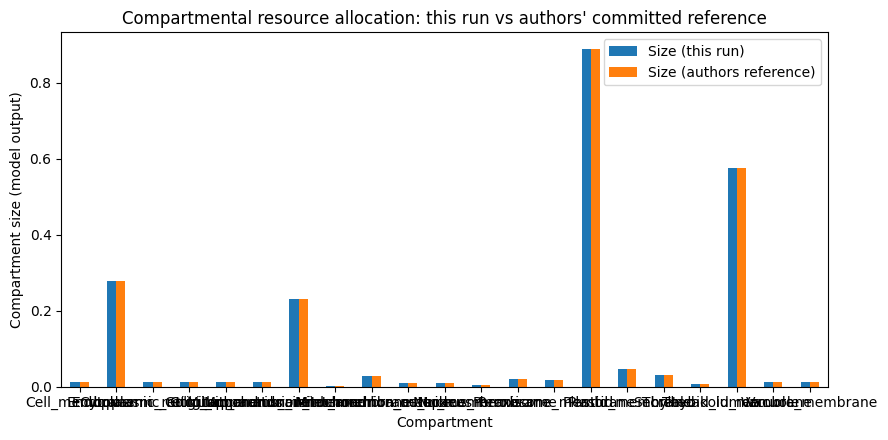

In [ ]:
import matplotlib.pyplot as plt

ref_comp = pd.read_csv(os.path.join(MODEL_ROOT, "outputs/compartments.out"), sep="\t")
ref_comp = ref_comp.rename(columns={"Size": "Size (authors reference)"})
merged = alloc.merge(ref_comp[["Compartment", "Size (authors reference)"]],
                     on="Compartment", how="outer")
plot_df = merged.set_index("Compartment")[["Size (this run)", "Size (authors reference)"]]
ax = plot_df.plot.bar(figsize=(9, 4.5), rot=0)
ax.set_ylabel("Compartment size (model output)")
ax.set_xlabel("Compartment")
ax.set_title("Compartmental resource allocation: this run vs authors' committed reference")
plt.tight_layout()
plt.show()

### 9. Result — resource allocation to macromolecular process machineries

RBA also predicts the concentration of each **macromolecular process machinery** (ribosomes, proteasomes, photosynthetic machinery, chaperones, …). The table shows the top processes by machinery concentration; this corresponds to the authors' `outputs/process_machineries.out`.

**日本語:** 各高分子プロセスのマシナリー濃度（リボソーム、プロテアソーム、光合成機構など）を表示します（著者の `process_machineries.out` に対応）。

In [ ]:
mach = results.process_machinery_concentrations()
mach_df = pd.DataFrame(
    [(p, mach[p]) for p in mach],
    columns=["Process", "Machinery concentration"]).sort_values(
    "Machinery concentration", ascending=False)
display(mach_df.head(15))
print(f"... {len(mach_df)} processes in total")

,Process,Machinery concentration
4,P_Translation_c,1.249255e-06
28,P_Translation_h,4.931798e-07
19,P_TIC_TOC2,3.896582e-07
8,P_Chaperone6010_plastid,3.698849e-07
16,P_Chaperone7090_plastid,3.610702e-07
21,P_TIC_TOC1,1.599601e-07
7,P_TOM,1.289964e-07
26,P_TIM17_23_SORT,1.046816e-07
11,P_TIM22cx,1.046816e-07
1,P_Chaperone_mitochondrion,5.314297e-08


... 31 processes in total


### 10. Quantitative check against the authors' reference growth rate + result export

Compares the predicted growth rate with the authors' committed reference `outputs/growth_rate.out` and the compartment sizes with `compartments.out`. A relative deviation within **2 %** is accepted as agreement (bisection tolerance 10⁻⁴ on μ ≈ 10⁻²–10⁻¹ h⁻¹ plus LP solver differences). The run then writes this run's own results in the authors' output format and a CSV export.

**日本語:** 予測増殖速度とコンパートメントサイズを著者の参照出力と比較します（相対差 2 % 以内を一致とみなす）。その後、本実行の結果を著者と同じ形式および CSV で保存します。

In [ ]:
ref_line = open(os.path.join(MODEL_ROOT, "outputs/growth_rate.out")).read().strip().split("\t")
ref_mu = float(ref_line[1])
rel_diff_mu = abs(results.mu_opt - ref_mu) / abs(ref_mu)
print(f"Growth rate: this run = {results.mu_opt:.6f} h^-1 | "
      f"authors' reference = {ref_mu:.6f} h^-1 | relative difference = {rel_diff_mu:.2e}")
assert rel_diff_mu < 0.02, "Growth rate deviates from the authors' reference by more than 2%"

merged["Rel. difference"] = (merged["Size (this run)"] - merged["Size (authors reference)"]).abs() \
    / merged["Size (authors reference)"].abs()
display(merged[["Compartment", "Size (this run)", "Size (authors reference)", "Rel. difference"]])
assert (merged["Rel. difference"] < 0.02).all(), "A compartment size deviates by more than 2%"

out_dir = "/content/rba_results"
os.makedirs(os.path.join(out_dir, "outputs"), exist_ok=True)
results.write(out_dir)  # authors' output format: growth_rate.out, compartments.out, ...
alloc.to_csv(os.path.join(out_dir, "outputs", "compartment_allocation_this_run.csv"), index=False)
mach_df.to_csv(os.path.join(out_dir, "outputs", "process_machineries_this_run.csv"), index=False)
print("Wrote:", sorted(os.listdir(os.path.join(out_dir, "outputs"))))

Growth rate: this run = 0.210190 h^-1 | authors' reference = 0.210190 h^-1 | relative difference = 0.00e+00


,Compartment,Size (this run),Size (authors reference),Rel. difference
0,Cell_membrane,0.012602,0.012602,1.270316e-06
1,Cytoplasm,0.276915,0.276904,3.800109e-05
2,Endoplasmic_reticulum,0.011878,0.011878,2.920910e-16
3,Endoplasmic_reticulum_membrane,0.011878,0.011878,2.920910e-16
4,Golgi_apparatus,0.011878,0.011878,2.920910e-16
5,Golgi_apparatus_membrane,0.011878,0.011878,2.920910e-16
6,Mitochondrion_inner_membrane,0.231543,0.231555,4.832322e-05
7,Mitochondrion_intermembrane_space,0.001810,0.001810,2.267000e-06
8,Mitochondrion_matrix,0.028593,0.028593,2.422024e-08
9,Mitochondrion_outer_membrane,0.010288,0.010288,3.021071e-07


Wrote: ['compartment_allocation_this_run.csv', 'compartments.out', 'enzymes.out', 'growth_rate.out', 'process_machineries.out', 'process_machineries_this_run.csv', 'reactions.out']


### 11. Validation record and references

Prints the environment and provenance actually observed during this run (versions, model/engine commits, measured solve time).

**日本語:** 本実行で観測された環境・版・計測時間を記録として表示します。

In [ ]:
import platform
print("Validation record (observed in this run)")
print("  Python        :", platform.python_version())
print("  Platform      :", platform.platform())
print("  rba (RBApy)   :", rba.__version__)
print("  scipy         :", scipy.__version__)
print("  LP backend    : scipy.optimize.linprog (HiGHS) on the authors' ConstraintMatrix")
print("  Model commit  : 973f00e0618493e6df6af52bdde55686168fda62 (RBA-models, PlantCellRBA)")
print("  Engine        : rbapy==3.0.3 == commit 7aba827e3f2c8ac37808aeaa8ec056372c7cfc1d")
print(f"  Solve wall time: {elapsed:.1f} s ({n_iter} LPs)")

Validation record (observed in this run)
  Python        : 3.13.16
  Platform      : Linux-6.6.159+-x86_64-with-glibc2.39
  rba (RBApy)   : 3.0.3
  scipy         : 1.16.3
  LP backend    : scipy.optimize.linprog (HiGHS) on the authors' ConstraintMatrix
  Model commit  : 973f00e0618493e6df6af52bdde55686168fda62 (RBA-models, PlantCellRBA)
  Engine        : rbapy==3.0.3 == commit 7aba827e3f2c8ac37808aeaa8ec056372c7cfc1d
  Solve wall time: 6.8 s (16 LPs)


## Interpretation, limitations, references

**Interpretation.** The solved condition yields a positive relative growth rate `mu_opt` (h⁻¹) and a compartmental allocation pattern dominated by the compartments hosting the cell's macromolecular growth machinery; predicted allocation agrees with the authors' committed reference for the same model within 2 %. This demonstrates the paper's central claim in miniature: an RBA model predicts growth and resource allocation **without empirical constraints**, as an emergent outcome of the LP + bisection optimization.

**Limitations.** Single fixed condition (no environmental sweeps); no comparison with Farquhar CO₂-response characteristics or C:N data; the authors' reference outputs were generated with an unrecorded (likely commercial) LP solver, so small numerical differences are expected; a one-example run does not verify dataset-level results.

**References.**
- A. Goelzer et al., "Resource allocation modeling for autonomous prediction of plant cell phenotypes", *Metabolic Engineering* 83 (2024) 86–101, [DOI 10.1016/j.ymben.2024.03.009](https://doi.org/10.1016/j.ymben.2024.03.009)
- A. Bulović et al., "Automated generation of bacterial resource allocation models", *Metabolic Engineering* 55 (2019) 12–22 (RBApy), [DOI 10.1016/j.ymben.2019.06.001](https://doi.org/10.1016/j.ymben.2019.06.001)
- Engine: https://github.com/RBAgroup/RBApy @ `7aba827e3f2c8ac37808aeaa8ec056372c7cfc1d` (GPLv3) — Model: https://github.com/RBAgroup/RBA-models @ `973f00e0618493e6df6af52bdde55686168fda62`, `PlantCellRBA/` (cc-by-nc 4.0)

**日本語:** 本デモは、RBA モデルが経験的制約なしに増殖速度とリソース割り当てを予測すること（論文の主張の核）を最小例で示します。単一条件・単一例であり、環境スイープや Farquhar 特性との比較、データセット全体の検証は含みません。著者の参照出力は商用ソルバー（推定）で生成されているため、数値の微小差は想定内です。